# Capítulo 5 · Actividad: ¿cuánto consume este auto?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/02_actividad_mpg_regresion.ipynb)

Entrena una **regresión** que prediga el rendimiento de un auto en **millas por galón** (`mpg`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

| Variable | Significado |
|---|---|
| `mpg` | **Target**: millas por galón (más alto = consume menos) |
| `cylinders` | Número de cilindros |
| `displacement` | Cilindrada del motor (pulgadas cúbicas) |
| `horsepower` | Potencia (caballos de fuerza) |
| `weight` | Peso (libras) |
| `acceleration` | Segundos para ir de 0 a 60 mph |
| `model_year` | Año del modelo (70 = 1970) |
| `origin` | Región de origen: `usa`, `europe` o `japan` |
| `name` | Nombre del auto |

Como mínimo, tu notebook debe incluir:

- Un **modelo lineal base**: coeficientes, métricas de error y $R^2$.
- Los mismos modelos que vimos en clase: regresión simple, lineal múltiple, Ridge, Lasso, polinomial y RANSAC.
- Una **tabla final** comparando los modelos con validación cruzada y test, y tus **conclusiones**: ¿qué modelo elegirías y por qué?

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

---
## Cómo leer este notebook

Este notebook sigue el mismo camino que la clase de regresión lineal:

```
explorar → decidir columnas → separar train/test → outliers → preparar → modelos → comparar → evaluar en test → concluir
```

Lee cada explicación **antes** de ejecutar su celda. Las partes **"Qué vemos"** interpretan el resultado que acabas de obtener.

**La idea central:** en el Titanic predecíamos una categoría (sobrevivió o no): eso es **clasificación**. Aquí predecimos un número (millas por galón): eso es **regresión**. Por eso cambian las métricas: ya no contamos aciertos, medimos **qué tan lejos** queda cada predicción del valor real.

## 1. Importar librerías

Todos los imports van al principio para que el notebook funcione con *Restart & Run All*.

- `set_config(transform_output="pandas")`: hace que scikit-learn devuelva tablas con nombres de columna, no arrays sin nombres. Así podemos ver qué significa cada coeficiente.
- `SEED = 42`: fija el azar. Sin esto, cada ejecución daría una separación distinta y resultados distintos.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, RANSACRegressor, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

: 

: 

## 2. Cargar y explorar los datos (EDA)

Antes de modelar hay que conocer los datos. Cada fila es un auto.

In [2]:
df = pd.read_csv(DATA_DIR / "mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


### 2.1 Tamaño, tipos y resumen

`info()` muestra tipos y valores no nulos. `describe()` resume las columnas numéricas.

In [3]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (398, 9)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [4]:
df.describe().round(2)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.00,398.00,398.00,392.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.47,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.49,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,93.50,2803.50,15.50,76.00
75%,29.00,8.00,262.00,126.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


**Qué vemos:** hay 398 autos. `horsepower` tiene 392 valores, así que le faltan 6. `mpg` va de 9 a 46.6, con media 23.5. Las escalas son muy distintas: `weight` llega a 5140 y `cylinders` a 8. Eso importará para Ridge y Lasso.

### 2.2 Nulos y duplicados

In [5]:
print("Valores nulos por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

df[df["horsepower"].isna()][["name", "mpg", "cylinders", "weight"]]

Valores nulos por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Filas duplicadas: 0


,name,mpg,cylinders,weight
32,ford pinto,25.0,4,2046
126,ford maverick,21.0,6,2875
330,renault lecar deluxe,40.9,4,1835
336,ford mustang cobra,23.6,4,2905
354,renault 18i,34.5,4,2320
374,amc concord dl,23.0,4,3035


**Qué vemos:** no hay duplicados y solo faltan 6 valores de `horsepower`. Son autos normales, sin nada que indique un error sistemático. Con tan pocos datos, cada auto cuenta, así que imputaremos en vez de borrar filas.

### 2.3 La variable objetivo

Miramos primero lo que queremos predecir.

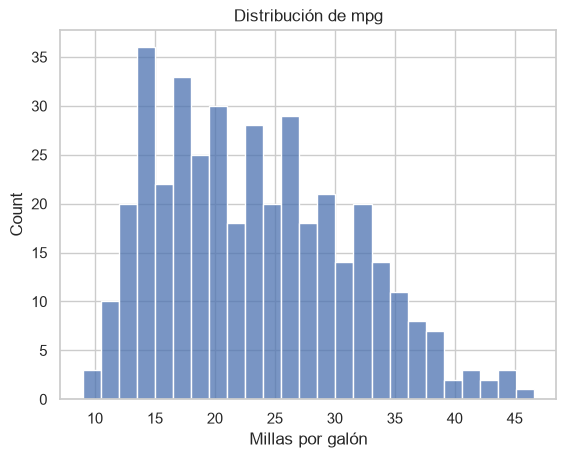

In [6]:
ax = sns.histplot(data=df, x="mpg", bins=25)
ax.set_title("Distribución de mpg")
ax.set_xlabel("Millas por galón")
plt.show()

**Qué vemos:** la mayoría está entre 15 y 30 mpg, con una cola hacia la derecha de autos muy eficientes. No hay un pico artificial en el máximo, a diferencia del tope que vimos en California.

### 2.4 Correlaciones

La correlación va de -1 a 1 y mide qué tan bien una **línea recta** describe la relación entre dos variables. Solo se calcula con columnas numéricas.

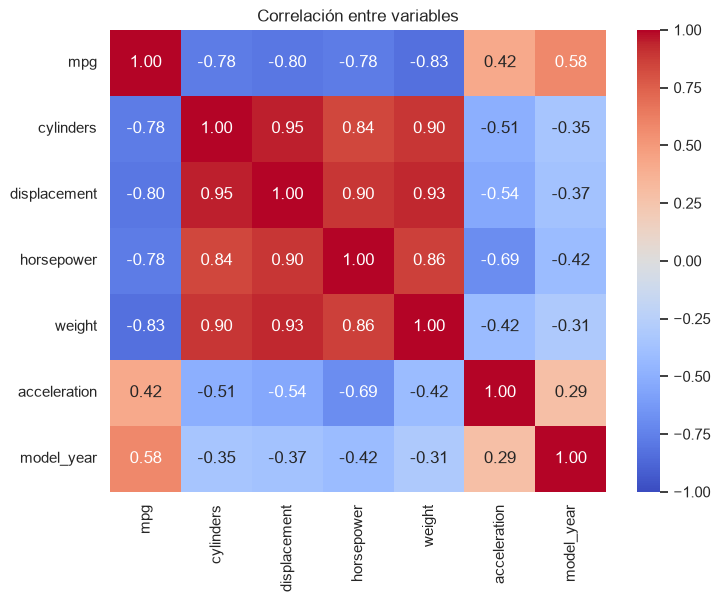

In [7]:
correlaciones = df.select_dtypes("number").corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

**Qué vemos:**

- `weight` es la variable más relacionada con `mpg` (-0.83): los autos pesados recorren menos millas por galón.
- `cylinders`, `displacement`, `horsepower` y `weight` también están muy correlacionadas **entre sí**. Es lógico: un auto grande suele tener un motor grande y potente. A esto se le llama **multicolinealidad**, y hace difícil interpretar cada coeficiente por separado.

### 2.5 Mirar las relaciones

Una correlación no muestra la forma de la relación. Por eso también graficamos.

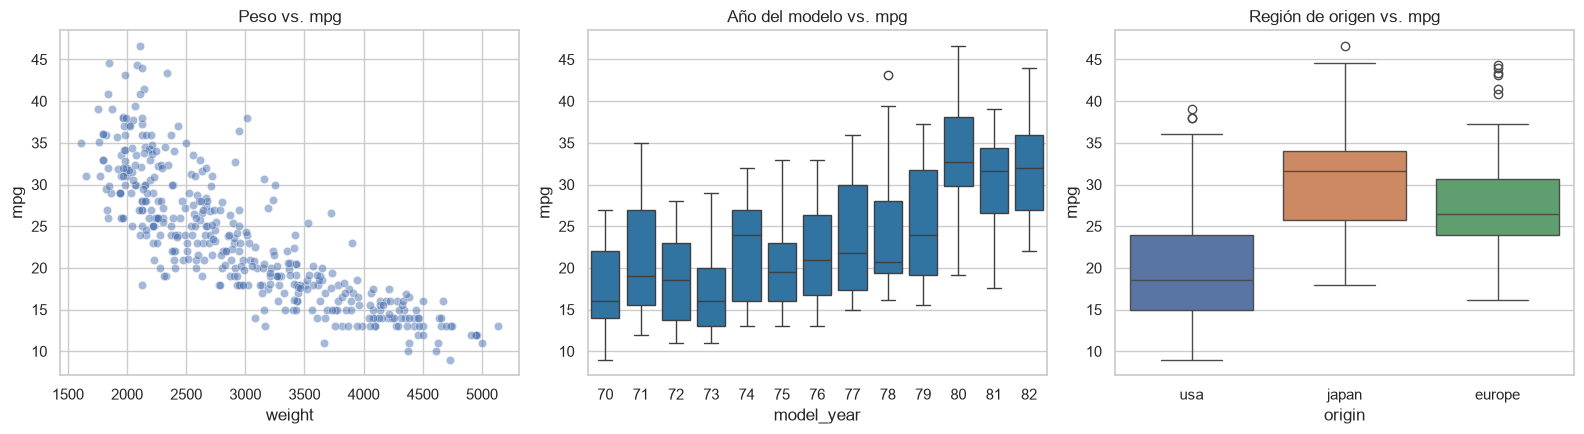

Peso mediano por región:
origin
europe    2240.0
japan     2155.0
usa       3365.0
Name: weight, dtype: float64


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(data=df, x="weight", y="mpg", alpha=0.5, ax=axes[0])
axes[0].set_title("Peso vs. mpg")

sns.boxplot(data=df, x="model_year", y="mpg", color="tab:blue", ax=axes[1])
axes[1].set_title("Año del modelo vs. mpg")

sns.boxplot(data=df, x="origin", y="mpg", hue="origin", ax=axes[2])
axes[2].set_title("Región de origen vs. mpg")

plt.tight_layout()
plt.show()

print("Peso mediano por región:")
print(df.groupby("origin")["weight"].median())

**Qué vemos:**

- **Peso:** la nube de puntos se **curva**: baja rápido al principio y luego más lento. Una recta no la seguirá del todo, y por eso esperamos que el modelo polinomial ayude.
- **Año:** los autos más nuevos tienden a rendir más.
- **Origen:** los autos de `usa` rinden menos (mediana 18.5) que los de `europe` (26.5) y `japan` (31.6). Cuidado: esto no significa que el país cause el consumo. Los autos de `usa` de estos datos también son mucho más pesados, y el modelo múltiple nos ayudará a separar esos efectos.

## 3. Decidir qué hacer con cada columna

| Columna | Tipo | Decisión | Por qué |
|---|---|---|---|
| `mpg` | Numérica | Es el **target** (`y`) | Es lo que queremos predecir |
| `name` | Texto | **La quitamos** | Tiene 305 valores distintos en 398 filas: casi cada auto tiene el suyo, así que el modelo no aprende una regla general |
| `origin` | Nominal | **One-hot** | Son categorías sin orden. Numerarlas inventaría un orden falso |
| `cylinders` | Numérica discreta | La dejamos **numérica** | Más cilindros sí significa "más": hay un orden real. Además, 3 y 5 cilindros casi no aparecen, y como categorías tendrían muy pocos ejemplos |
| `horsepower` | Numérica | **Imputar con la mediana** | Faltan 6 valores. La mediana resiste los valores extremos |
| Las demás | Numéricas | Escalar | Ridge y Lasso dependen de la escala |

## 4. Separar train y test

Ahora guardamos un 20 % de los autos y **no lo miramos hasta el final**. Ese es el conjunto de test: simula autos nuevos que el modelo nunca vio.

- `X` son las variables de entrada e `y` es lo que queremos predecir.
- No usamos `stratify`, porque `y` es un número y no hay clases que equilibrar.
- `KFold` divide train en 5 partes para la validación cruzada. Es el mismo reparto para todos los modelos, así la comparación es justa.

In [9]:
X = df.drop(columns=["mpg", "name"])
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (318, 7) | Test: (80, 7)


## 5. Outliers

Buscamos candidatos con la regla del IQR. Los límites salen **solo de train**: si usáramos test, le daríamos al proceso información de autos que se supone que aún no conocemos.

Un outlier es un **candidato**: todavía hay que decidir si es un error o un valor raro pero real.

In [10]:
columnas_numericas = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]

q1 = X_train[columnas_numericas].quantile(0.25)
q3 = X_train[columnas_numericas].quantile(0.75)
iqr = q3 - q1
es_outlier = (X_train[columnas_numericas] < q1 - 1.5 * iqr) | (X_train[columnas_numericas] > q3 + 1.5 * iqr)

print(es_outlier.sum())

# Vemos quiénes son, usando su nombre en la tabla original
df.loc[es_outlier[es_outlier.any(axis=1)].index, ["name", "horsepower", "acceleration", "cylinders", "weight", "mpg"]].sort_values("horsepower")

cylinders        0
displacement     0
horsepower      10
weight           0
acceleration     5
model_year       0
dtype: int64


,name,horsepower,acceleration,cylinders,weight,mpg
326,vw dasher (diesel),48.0,23.7,4,2335,43.4
59,volkswagen type 3,54.0,23.5,4,2254,23.0
299,peugeot 504,71.0,24.8,4,3190,27.2
11,plymouth 'cuda 340,160.0,8.0,8,3609,14.0
28,hi 1200d,193.0,18.5,8,4732,9.0
90,mercury marquis brougham,198.0,11.5,8,4952,12.0
26,chevy c20,200.0,15.0,8,4376,10.0
67,mercury marquis,208.0,11.0,8,4633,11.0
27,dodge d200,210.0,13.5,8,4382,11.0
7,plymouth fury iii,215.0,8.5,8,4312,14.0


**Qué vemos y qué decidimos:** el IQR marca 10 valores de `horsepower` y 5 de `acceleration`. Son autos reales: grandes V8 como el Chevrolet Impala o el Buick Electra, el Plymouth 'Cuda y autos lentos como un Volkswagen diésel. Sus valores tienen sentido, así que **no parecen errores**.

**Decisión: no los recortamos.** En la clase de California sí se recortaron valores extremos, pero aquí estos autos son justo los que enseñan al modelo qué pasa con motores grandes. Con solo 318 autos en train, no conviene quitarles información.

## 6. Preparar los datos con un `ColumnTransformer`

Cada tipo de columna necesita un tratamiento distinto, y `ColumnTransformer` aplica cada uno a sus columnas:

- **Numéricas:** imputar con la mediana y luego estandarizar. `StandardScaler` deja cada variable con media 0 y desviación 1.
- **`origin`:** one-hot con `drop="first"`. Si conociéramos dos de las columnas, la tercera ya estaría determinada, y esa redundancia exacta le da problemas a una regresión lineal. La categoría eliminada, `europe`, se vuelve la referencia.
- `handle_unknown="ignore"`: evita un error si en datos nuevos apareciera una región desconocida.

Lo importante es que **todavía no aprende nada**: solo es la receta. Al meterla en un `Pipeline`, cada `fit` aprende medianas y medias solo con los datos de entrenamiento de ese momento. Así evitamos la fuga de información, incluso dentro de cada fold.

In [11]:
columnas_categoricas = ["origin"]

pipeline_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
])

preprocesador = ColumnTransformer([
    ("numericas", pipeline_numerico, columnas_numericas),
    ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), columnas_categoricas),
], verbose_feature_names_out=False)

## 7. Regresión lineal simple

Empezamos con lo más sencillo: una sola variable, una recta.

$$\widehat{\text{mpg}} = \beta_0 + \beta_1 \cdot \text{weight}$$

- $\beta_0$ (**intercepto**): el valor de la recta cuando el peso es 0.
- $\beta_1$ (**pendiente**): cuánto cambia `mpg` por cada libra adicional.

El método **OLS** elige la recta que hace más pequeña la suma de los errores al cuadrado. Usamos `weight` porque fue la variable más correlacionada. No escalamos ni imputamos: `weight` no tiene nulos, y así la pendiente queda en unidades fáciles de entender.

Los dobles corchetes `X_train[["weight"]]` son necesarios porque scikit-learn espera una tabla, no una columna suelta.

In [12]:
modelo_simple = LinearRegression()
modelo_simple.fit(X_train[["weight"]], y_train)

beta_0 = modelo_simple.intercept_
beta_1 = modelo_simple.coef_[0]

print(f"Intercepto β0 = {beta_0:.2f}")
print(f"Pendiente  β1 = {beta_1:.5f}")
print(f"Por cada 1000 libras más, el modelo predice {beta_1 * 1000:.1f} mpg")

Intercepto β0 = 46.78
Pendiente  β1 = -0.00781
Por cada 1000 libras más, el modelo predice -7.8 mpg


**Qué vemos:** cada 1000 libras adicionales restan unas 7.8 mpg. El intercepto (46.8) no tiene una lectura práctica, porque no existe un auto de 0 libras: solo es el punto donde arranca la recta.

La gráfica de la derecha muestra los **residuos**: residuo = valor real − valor predicho. Si el modelo es adecuado, deben repartirse al azar alrededor de 0, sin ninguna forma.

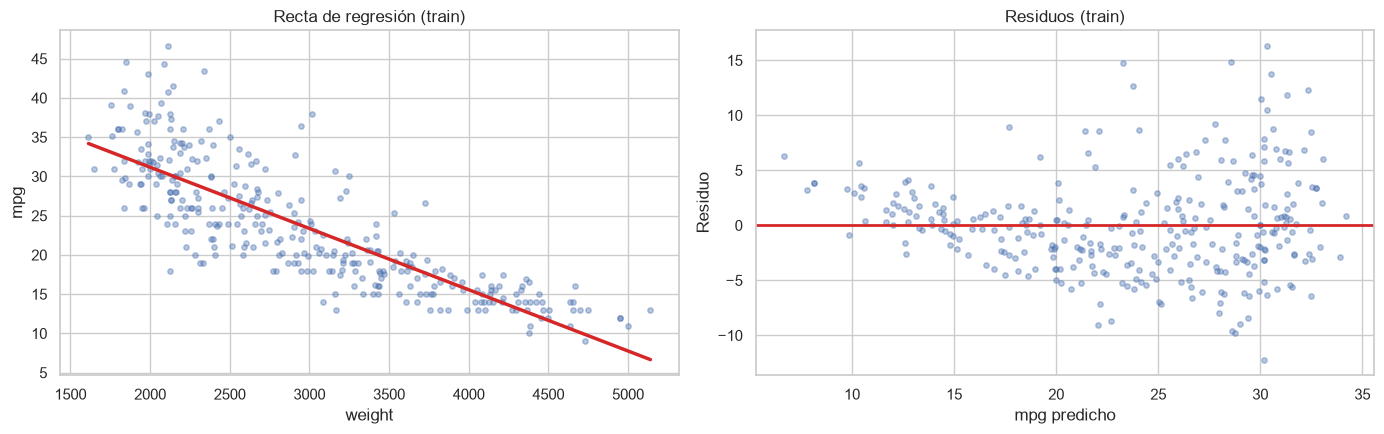

In [13]:
pred_train_simple = modelo_simple.predict(X_train[["weight"]])
residuos = y_train - pred_train_simple

recta_x = pd.DataFrame({"weight": np.linspace(X_train["weight"].min(), X_train["weight"].max(), 100)})
recta_y = modelo_simple.predict(recta_x)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(X_train["weight"], y_train, alpha=0.4, s=15)
axes[0].plot(recta_x["weight"], recta_y, color="tab:red", linewidth=2.5)
axes[0].set_xlabel("weight")
axes[0].set_ylabel("mpg")
axes[0].set_title("Recta de regresión (train)")

axes[1].scatter(pred_train_simple, residuos, alpha=0.4, s=15)
axes[1].axhline(0, color="tab:red", linewidth=2)
axes[1].set_xlabel("mpg predicho")
axes[1].set_ylabel("Residuo")
axes[1].set_title("Residuos (train)")

plt.tight_layout()
plt.show()

**Qué vemos:** los residuos **no** se reparten al azar. Con predicciones bajas (10 a 15 mpg) quedan sobre todo por encima de 0, entre 20 y 25 mpg quedan más por debajo, y con predicciones altas se dispersan mucho más. Ese patrón indica que una recta deja algo sin capturar.

## 8. Modelo lineal base: regresión múltiple

Ahora usamos todas las variables. Este será nuestro **modelo base**: el punto de comparación que los demás deben superar.

$$\widehat{\text{mpg}} = \beta_0 + \beta_1 X_1 + \dots + \beta_k X_k$$

Un `Pipeline` encadena la preparación y el modelo. Al estar estandarizadas, los coeficientes numéricos se pueden comparar entre sí: cada uno indica cuántas mpg cambian al subir **una desviación estándar** esa variable, manteniendo las demás fijas.

Intercepto: 25.48


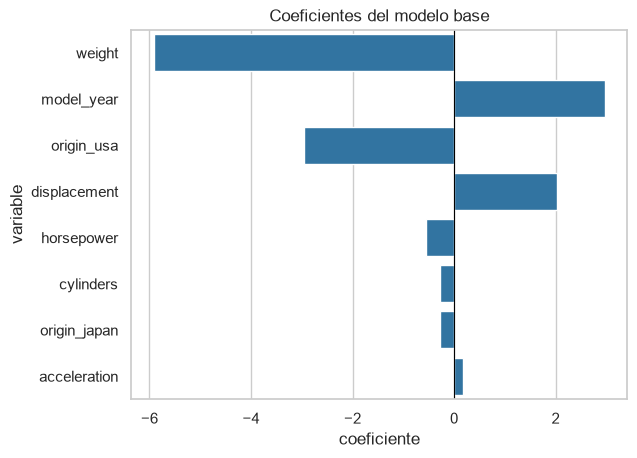

,variable,coeficiente
3,weight,-5.912
5,model_year,2.971
7,origin_usa,-2.948
1,displacement,2.036
2,horsepower,-0.545
0,cylinders,-0.279
6,origin_japan,-0.274
4,acceleration,0.186


In [14]:
modelo_lineal = Pipeline([
    ("preprocesador", preprocesador),
    ("regresion", LinearRegression()),
])
modelo_lineal.fit(X_train, y_train)

nombres_variables = modelo_lineal.named_steps["preprocesador"].get_feature_names_out()
coeficientes = pd.DataFrame({
    "variable": nombres_variables,
    "coeficiente": modelo_lineal.named_steps["regresion"].coef_,
}).sort_values("coeficiente", key=abs, ascending=False)

print(f"Intercepto: {modelo_lineal.named_steps['regresion'].intercept_:.2f}")

ax = sns.barplot(data=coeficientes, x="coeficiente", y="variable", color="tab:blue")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coeficientes del modelo base")
plt.show()

coeficientes.round(3)

**Qué vemos:**

- **`weight` (-5.9)** es el coeficiente más fuerte: con las demás variables fijas, un auto más pesado rinde menos.
- **`model_year` (+3.0):** los autos más nuevos rinden más, incluso con el mismo peso y motor.
- **`origin_usa` (-2.9):** este no se mide en desviaciones, sino frente a la referencia. Comparado con un auto europeo de características iguales, el modelo predice 2.9 mpg menos.
- **`origin_japan` (-0.3):** casi igual que un europeo. Fíjate: en la gráfica, Japón tenía la mediana más alta, pero con las demás variables fijas esa ventaja desaparece. Buena parte de ella se explicaba por las otras características de sus autos.
- **`displacement` (+2.0)** parece decir que un motor más grande rinde más, lo que contradice su correlación de -0.80. Esta es la **multicolinealidad** en acción: `displacement` y `weight` se mueven juntas, y el modelo reparte su efecto de una manera difícil de interpretar. Por eso no conviene leer estos coeficientes por separado.

El intercepto (25.5) es la predicción para un auto europeo con valores promedio.

## 9. Métricas de error y $R^2$

Las métricas de regresión miden la distancia entre el valor real y la predicción:

| Métrica | Qué significa | Mejor valor |
|---|---|---|
| **MSE** | Promedio de los errores al cuadrado. Castiga mucho los errores grandes, pero queda en unidades al cuadrado | Bajo |
| **RMSE** | Raíz del MSE. Vuelve a mpg, y es la métrica principal de la clase | Bajo |
| **MAE** | Promedio del error absoluto: el error típico, más fácil de explicar | Bajo |
| **MAPE** | Error promedio como porcentaje del valor real (0.10 = 10 %) | Bajo |
| **$R^2$** | Proporción de la variación de `mpg` que explica el modelo. 1 es perfecto; 0 equivale a predecir siempre la media | Alto |
| **$R^2$ ajustado** | $R^2$ con penalización por usar más variables | Alto |

Por ahora las calculamos en **train**. Test sigue guardado hasta el final.

In [15]:
def metricas_regresion(y_real, y_pred, n_variables):
    "Métricas principales de una regresión."
    n = len(y_real)
    r2 = r2_score(y_real, y_pred)
    return {
        "MSE": mean_squared_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "MAPE": mean_absolute_percentage_error(y_real, y_pred),
        "R²": r2,
        "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - n_variables - 1),
    }


pd.DataFrame({
    "Simple (weight)": metricas_regresion(y_train, pred_train_simple, n_variables=1),
    "Lineal múltiple": metricas_regresion(y_train, modelo_lineal.predict(X_train), n_variables=len(nombres_variables)),
}).round(3)

,Simple (weight),Lineal múltiple
MSE,19.782,11.355
RMSE,4.448,3.370
MAE,3.359,2.605
MAPE,0.147,0.120
R²,0.684,0.819
R² ajustado,0.683,0.814


**Qué vemos:** usar todas las variables reduce el error frente a la recta simple y sube el $R^2$. Como son datos de train, este resultado es optimista: el modelo ya vio estos autos. Para estimar cómo se comportará con autos nuevos usamos validación cruzada.

## 10. Ridge y Lasso: regularización

Un modelo con muchos coeficientes grandes puede ajustarse demasiado a train. La **regularización** añade una penalización por coeficientes grandes, y `alpha` controla su fuerza.

- **Ridge:** encoge todos los coeficientes, sin llevarlos a cero. Ayuda con la multicolinealidad.
- **Lasso:** también encoge, pero puede dejar coeficientes en exactamente 0, lo que elimina variables.

La penalización se aplica al tamaño de los coeficientes, y ese tamaño depende de las unidades. Por eso estos modelos **sí necesitan variables escaladas**. Es la diferencia con un árbol, al que la escala no le importa.

Usamos los mismos valores que en clase: `alpha=1.0` para Ridge y `alpha=0.01` para Lasso.

In [16]:
modelo_ridge = Pipeline([("preprocesador", preprocesador), ("regresion", Ridge(alpha=1.0))])
modelo_lasso = Pipeline([("preprocesador", preprocesador), ("regresion", Lasso(alpha=0.01))])

modelo_ridge.fit(X_train, y_train)
modelo_lasso.fit(X_train, y_train)

pd.DataFrame({
    "Lineal": modelo_lineal.named_steps["regresion"].coef_,
    "Ridge": modelo_ridge.named_steps["regresion"].coef_,
    "Lasso": modelo_lasso.named_steps["regresion"].coef_,
}, index=nombres_variables).round(3)

,Lineal,Ridge,Lasso
cylinders,-0.279,-0.229,-0.073
displacement,2.036,1.730,1.532
horsepower,-0.545,-0.578,-0.475
weight,-5.912,-5.683,-5.742
acceleration,0.186,0.142,0.160
model_year,2.971,2.938,2.941
origin_japan,-0.274,-0.179,-0.094
origin_usa,-2.948,-2.790,-2.683


**Qué vemos:** Lasso encogió sobre todo `displacement` (de 2.0 a 1.5) y `cylinders`, que eran variables redundantes. Con estos `alpha` tan pequeños ninguna llega a 0 y los cambios son modestos, así que esperamos resultados muy parecidos a los del modelo lineal.

## 11. Regresión polinomial: permitir curvas

Vimos que la relación con el peso se curva. `PolynomialFeatures(degree=2)` crea variables nuevas: cada variable al cuadrado (`weight²`) y los productos entre variables (`weight × model_year`). El modelo sigue siendo lineal en sus coeficientes, pero ahora puede dibujar curvas e interacciones.

Después de crear esas variables volvemos a escalar, porque un cuadrado queda en otra escala.

**¿Qué grado usar?** Un grado mayor da más flexibilidad, pero también más riesgo de memorizar. Lo probamos con validación cruzada. `scoring="neg_root_mean_squared_error"` devuelve el RMSE en negativo porque scikit-learn siempre busca el número más alto; por eso le cambiamos el signo.

In [17]:
def crear_polinomial(grado):
    return Pipeline([
        ("preprocesador", preprocesador),
        ("poli", PolynomialFeatures(degree=grado, include_bias=False)),
        ("escalador_poli", StandardScaler()),
        ("regresion", LinearRegression()),
    ])


filas_grado = []
for grado in [1, 2, 3]:
    resultado = cross_validate(crear_polinomial(grado), X_train, y_train, cv=cv,
                               scoring="neg_root_mean_squared_error", return_train_score=True)
    filas_grado.append({
        "grado": grado,
        "RMSE train": -resultado["train_score"].mean(),
        "RMSE validación": -resultado["test_score"].mean(),
    })

pd.DataFrame(filas_grado).set_index("grado").round(3)

,RMSE train,RMSE validación
grado,,
1,3.357,3.478
2,2.456,3.153
3,1.527,15.910


**Qué vemos:** esta tabla es la mejor lección del notebook.

- **Grado 1:** es el modelo lineal.
- **Grado 2:** baja el error en train y también en validación. La curva aporta algo real.
- **Grado 3:** el error en train baja a 1.5, pero en validación **se dispara a casi 16**. Esto es **sobreajuste**: el modelo memoriza train y falla con autos que no vio.

Por eso nunca se elige un modelo solo por su resultado en train. Nos quedamos con el grado 2.

Fíjate en que el grado 2 aún tiene una brecha entre train (2.5) y validación (3.2). En la sección 13 intentaremos reducirla.

## 12. RANSAC: resistir a los datos raros

OLS intenta acercarse a **todos** los puntos, así que unos pocos muy alejados pueden mover la recta. RANSAC funciona de otra forma:

1. Elige una muestra al azar y ajusta una recta.
2. Cuenta cuántos puntos quedan cerca: los **inliers**.
3. Repite muchas veces y se queda con la mejor opción.
4. Ajusta el modelo final solo con los inliers.

In [18]:
modelo_ransac = Pipeline([
    ("preprocesador", preprocesador),
    ("regresion", RANSACRegressor(LinearRegression(), random_state=SEED)),
])
modelo_ransac.fit(X_train, y_train)

inliers = modelo_ransac.named_steps["regresion"].inlier_mask_
print(f"Inliers: {inliers.sum()} de {len(inliers)} autos ({inliers.mean():.0%})")

Inliers: 267 de 318 autos (84%)


**Qué vemos:** RANSAC usó el 84 % de los autos y dejó fuera el resto al ajustar la recta. Si esos autos descartados son reales, el modelo no aprende de ellos y puede cometer errores grandes cuando se encuentre autos parecidos.

## 13. Un intento adicional: polinomial con Ridge

La actividad pide el mejor modelo posible. Tenemos dos pistas: el polinomial mejora, pero todavía sobreajusta un poco, y Ridge sirve para controlar el sobreajuste. Entonces los combinamos.

Para elegir `alpha` usamos `GridSearchCV`, igual que con el árbol: prueba cada valor con validación cruzada, **solo dentro de train**.

In [19]:
busqueda = GridSearchCV(
    Pipeline([
        ("preprocesador", preprocesador),
        ("poli", PolynomialFeatures(degree=2, include_bias=False)),
        ("escalador_poli", StandardScaler()),
        ("regresion", Ridge()),
    ]),
    {"regresion__alpha": [0.1, 1, 10, 100, 1000]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
)
busqueda.fit(X_train, y_train)

mejor_alpha = busqueda.best_params_["regresion__alpha"]
print("Mejor alpha:", mejor_alpha)

resultados_alpha = pd.DataFrame({
    "alpha": busqueda.cv_results_["param_regresion__alpha"],
    "RMSE validación": -busqueda.cv_results_["mean_test_score"],
})
resultados_alpha.round(3)

Mejor alpha: 10


,alpha,RMSE validación
0,0.1,3.072
1,1.0,2.969
2,10.0,2.955
3,100.0,3.255
4,1000.0,4.459


**Qué vemos:** el mejor valor es `alpha=10`. Con un `alpha` muy pequeño el modelo se ajusta de más; con uno muy grande (1000) lo encoge tanto que ya casi no aprende. El mejor punto está en medio.

## 14. Comparar los modelos con validación cruzada

Ahora ponemos todo en una tabla. Cada modelo se evalúa con **los mismos 5 folds**.

- **RMSE train:** error sobre los datos con que entrenó.
- **RMSE validación:** error sobre el fold que no vio. **Este número decide.**
- **Desviación:** cuánto varía entre folds.

Elegimos con validación, sin tocar test. Si eligiéramos con test, dejaría de ser una prueba independiente.

In [20]:
modelos = {
    "Simple (weight)": LinearRegression(),
    "Lineal múltiple": modelo_lineal,
    "Ridge": modelo_ridge,
    "Lasso": modelo_lasso,
    "Polinomial (grado 2)": crear_polinomial(2),
    "RANSAC": modelo_ransac,
    "Polinomial + Ridge": busqueda.best_estimator_,
}


def columnas_de(nombre):
    "El modelo simple solo usa weight; los demás usan todas las columnas."
    return ["weight"] if nombre.startswith("Simple") else list(X_train.columns)


filas = []
for nombre, modelo in modelos.items():
    resultado = cross_validate(modelo, X_train[columnas_de(nombre)], y_train, cv=cv,
                               scoring="neg_root_mean_squared_error", return_train_score=True)
    filas.append({
        "modelo": nombre,
        "RMSE train": -resultado["train_score"].mean(),
        "RMSE validación": -resultado["test_score"].mean(),
        "Desviación": resultado["test_score"].std(),
    })

comparacion_cv = pd.DataFrame(filas).set_index("modelo").sort_values("RMSE validación")
comparacion_cv.round(3)

,RMSE train,RMSE validación,Desviación
modelo,,,
Polinomial + Ridge,2.595,2.955,0.224
Polinomial (grado 2),2.456,3.153,0.232
Lasso,3.358,3.464,0.209
Ridge,3.358,3.471,0.206
Lineal múltiple,3.357,3.478,0.224
RANSAC,3.729,3.724,0.155
Simple (weight),4.442,4.493,0.193


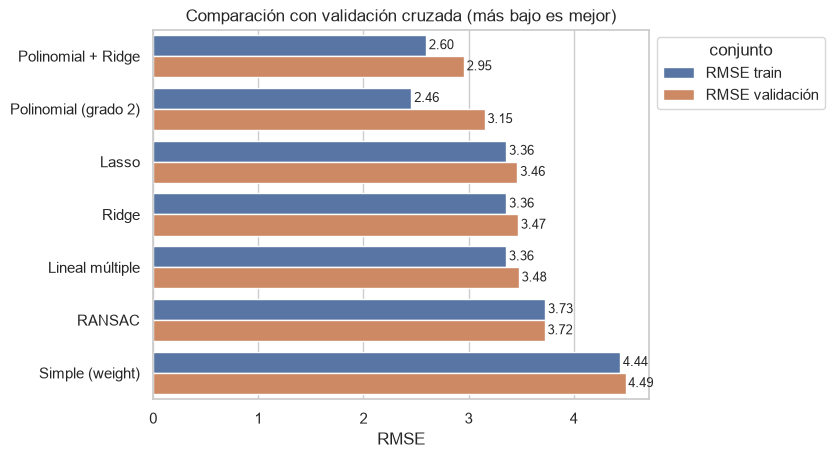

Modelo elegido con validación cruzada: Polinomial + Ridge


In [21]:
datos_grafica = (comparacion_cv[["RMSE train", "RMSE validación"]]
                 .reset_index()
                 .melt(id_vars="modelo", var_name="conjunto", value_name="RMSE"))

ax = sns.barplot(data=datos_grafica, x="RMSE", y="modelo", hue="conjunto")
ax.set_title("Comparación con validación cruzada (más bajo es mejor)")
ax.set_ylabel("")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", fontsize=9, padding=2)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

mejor_modelo = comparacion_cv["RMSE validación"].idxmin()
print("Modelo elegido con validación cruzada:", mejor_modelo)

**Qué vemos:**

- **Polinomial + Ridge** gana, con un error de validación cercano a 2.95 mpg. Fue el mejor de varios valores de `alpha` probados en estos folds, así que ese número puede ser un poco optimista.
- **Polinomial** queda segundo: las curvas e interacciones aportan más que cualquier otro cambio.
- **Lineal, Ridge y Lasso** casi empatan (alrededor de 3.47). Sus diferencias son mucho menores que la desviación entre folds, así que no podemos decir que uno sea mejor. Tiene sentido: aquí hay pocas variables, y el problema no era el exceso de coeficientes, sino la falta de curvas.
- **RANSAC** queda peor que el lineal en RMSE, porque descartó autos que sí son reales.
- **Simple** es el peor: una sola variable no alcanza.

## 15. Evaluación final en test

Ya elegimos, y ahora sí abrimos test. Entrenamos cada modelo con todo train y medimos en los 80 autos reservados. Mostramos todos para completar la tabla de la actividad, pero la elección ya está hecha.

In [22]:
filas_test = []
predicciones = {}
for nombre, modelo in modelos.items():
    columnas = columnas_de(nombre)
    modelo.fit(X_train[columnas], y_train)
    prediccion = modelo.predict(X_test[columnas])
    predicciones[nombre] = prediccion
    metricas = metricas_regresion(y_test, prediccion, n_variables=len(columnas))
    filas_test.append({"modelo": nombre, "RMSE test": metricas["RMSE"], "MAE test": metricas["MAE"],
                       "MAPE test": metricas["MAPE"], "R² test": metricas["R²"]})

tabla_final = comparacion_cv.join(pd.DataFrame(filas_test).set_index("modelo"))
tabla_final.round(3)

,RMSE train,RMSE validación,Desviación,RMSE test,MAE test,MAPE test,R² test
modelo,,,,,,,
Polinomial + Ridge,2.595,2.955,0.224,2.207,1.653,0.078,0.909
Polinomial (grado 2),2.456,3.153,0.232,2.380,1.750,0.081,0.895
Lasso,3.358,3.464,0.209,2.894,2.273,0.115,0.844
Ridge,3.358,3.471,0.206,2.886,2.281,0.116,0.845
Lineal múltiple,3.357,3.478,0.224,2.888,2.288,0.116,0.845
RANSAC,3.729,3.724,0.155,3.056,2.242,0.101,0.826
Simple (weight),4.442,4.493,0.193,3.859,3.118,0.143,0.723


**Qué vemos:**

- **La elección se confirma:** Polinomial + Ridge también es el mejor en test, con RMSE de 2.21, MAE de 1.65 y $R^2$ de 0.91. Traducido: en estos 80 autos, se equivoca en promedio unas 1.65 mpg, y explica cerca del 91 % de la variación de `mpg`.
- **Test salió mejor que validación.** Los 7 modelos tienen menos error en test que en validación. No significa que hayan mejorado: con solo 80 autos, parece que este test quedó algo más fácil. Por eso la validación cruzada, que usa 5 particiones, da una expectativa más prudente: un error cercano a **3 mpg**.
- **RANSAC es un caso interesante:** su MAE (2.24) es un poco mejor que el del lineal (2.29), pero su RMSE es peor (3.06 contra 2.89). Como RMSE castiga más los errores grandes, significa que le va bien con la mayoría de los autos, pero falla mucho con algunos.

### 15.1 Real vs. predicho

Si un modelo fuera perfecto, todos los puntos caerían sobre la línea punteada.

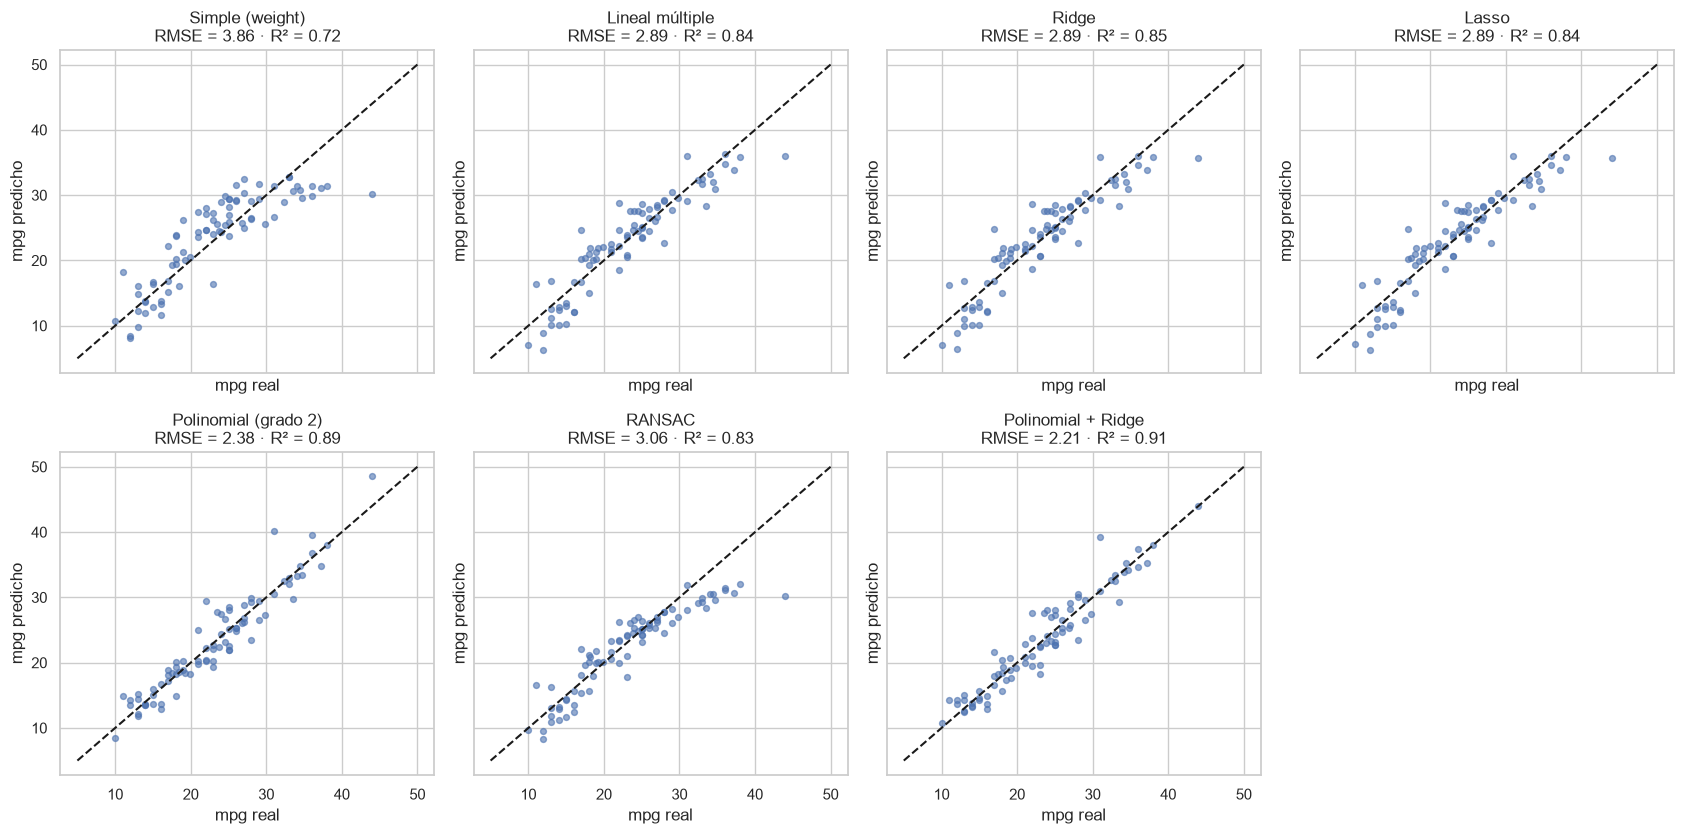

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5), sharex=True, sharey=True)
for (nombre, prediccion), ax in zip(predicciones.items(), axes.flat):
    ax.scatter(y_test, prediccion, alpha=0.6, s=18)
    ax.plot([5, 50], [5, 50], "k--")
    ax.set_title(f"{nombre}\nRMSE = {root_mean_squared_error(y_test, prediccion):.2f} · R² = {r2_score(y_test, prediccion):.2f}")
    ax.set_xlabel("mpg real")
    ax.set_ylabel("mpg predicho")
axes.flat[-1].set_visible(False)   # sobra un panel: son 7 modelos y 8 espacios
plt.tight_layout()
plt.show()

**Qué vemos:** en los modelos lineales los puntos forman una ligera curva: los autos de mayor rendimiento quedan por debajo de la línea. Por ejemplo, un auto de unas 44 mpg recibe una predicción cercana a 36 en el lineal y a 30 en RANSAC. En los dos modelos polinomiales, ese mismo auto queda mucho más cerca de la línea.

### 15.2 Residuos del modelo elegido

Comprobamos si queda algún patrón sin capturar.

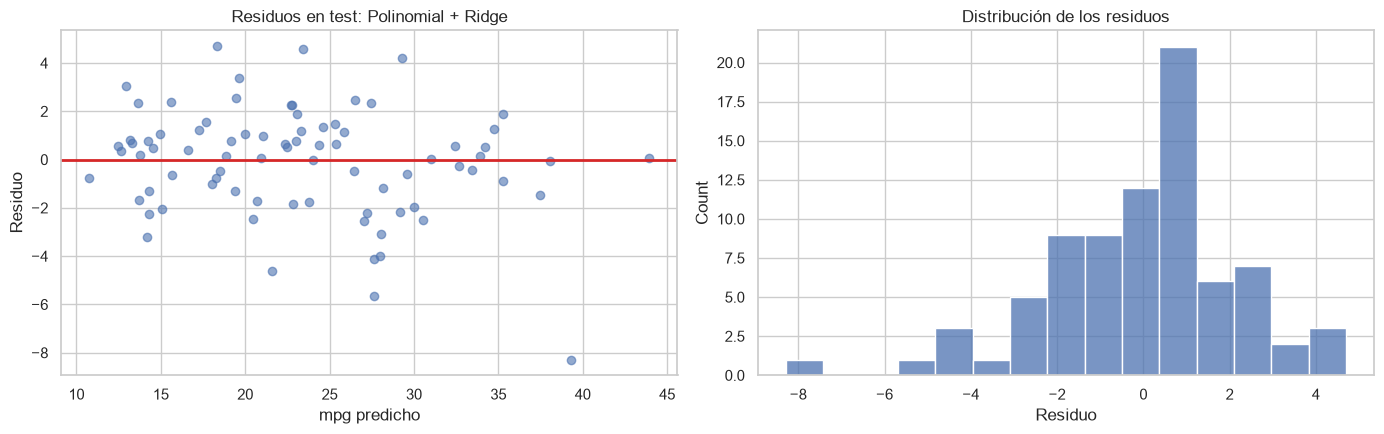

In [24]:
prediccion_final = predicciones[mejor_modelo]
residuos_final = y_test - prediccion_final

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(prediccion_final, residuos_final, alpha=0.6)
axes[0].axhline(0, color="tab:red", linewidth=2)
axes[0].set_xlabel("mpg predicho")
axes[0].set_ylabel("Residuo")
axes[0].set_title(f"Residuos en test: {mejor_modelo}")

sns.histplot(x=residuos_final, bins=15, ax=axes[1])
axes[1].set_xlabel("Residuo")
axes[1].set_title("Distribución de los residuos")

plt.tight_layout()
plt.show()

**Qué vemos:** los residuos se reparten alrededor de 0 y ya no se ve la curva del modelo simple. La mayoría queda entre -4 y 4 mpg. Hay un caso muy alejado, con un residuo cercano a -8: el modelo predijo unas 39 mpg para un auto que rinde cerca de 31. Un solo auto no invalida el modelo, pero conviene recordar que puede fallar con casos así.

### 15.3 Usar el modelo con un auto nuevo

Esta es la ventaja del `Pipeline`: le damos los datos crudos y él imputa, escala, codifica y predice con lo que aprendió en train. Este auto es un ejemplo inventado.

In [25]:
auto_nuevo = pd.DataFrame([{
    "cylinders": 4, "displacement": 120, "horsepower": 90, "weight": 2500,
    "acceleration": 16, "model_year": 80, "origin": "japan",
}])

modelo_final = modelos[mejor_modelo]
print(f"Rendimiento predicho: {modelo_final.predict(auto_nuevo)[0]:.1f} mpg")

Rendimiento predicho: 29.3 mpg


## 16. Conclusiones

**¿Qué modelo elegiría?** **Polinomial de grado 2 con Ridge (`alpha=10`)**, por tres razones:

1. Tuvo el menor error en validación cruzada (RMSE de 2.95 mpg), que fue el criterio de elección.
2. Test lo confirmó, con RMSE de 2.21 y $R^2$ de 0.91.
3. Tiene sentido con lo que vimos en el EDA: la relación con el peso se curva, y Ridge controla parte del sobreajuste que apareció al usar más variables.

**¿Qué error esperar?** Unas 3 mpg, tomando la validación cruzada como referencia prudente. El resultado de test es mejor, pero solo son 80 autos.

**¿Cuál es el costo?** Interpretabilidad. El modelo lineal es más fácil de explicar: si la meta fuera entender el efecto de cada variable y no predecir, podría preferirlo, aunque con cuidado por la multicolinealidad.

**Lo que aprendimos:**

- Lo que más mejoró el modelo fue permitir **curvas**. Ridge y Lasso casi no cambiaron nada por sí solos, pero Ridge sí ayudó combinado con el polinomial.
- Más complejidad no siempre es mejor: el grado 3 falló mucho en validación.
- Los valores que marcó el IQR parecían autos reales, así que los conservamos a propósito.

**Limitaciones:** son autos de 1970 a 1982. El modelo no sirve para autos actuales, ni para híbridos o eléctricos, y 398 autos son pocos para sacar conclusiones generales.

### Bitácora de decisiones

| Columna o paso | Problema | Decisión | Por qué |
|---|---|---|---|
| `name` | 305 valores distintos | Eliminarla | No generaliza |
| `horsepower` | 6 nulos | Imputar con la mediana dentro del `Pipeline` | Conserva los autos y evita fuga de información |
| `origin` | Categoría sin orden | One-hot con `drop="first"` | No inventa un orden y evita redundancia exacta |
| `cylinders` | Pocos valores distintos | Dejarla numérica | Tiene orden real, y 3 y 5 cilindros casi no aparecen |
| Outliers | 10 en `horsepower`, 5 en `acceleration` | No tocarlos | Parecen autos reales |
| Escalado | Unidades muy distintas | `StandardScaler` | Ridge y Lasso lo necesitan, y permite comparar coeficientes |
| Modelo | Relación curva | Polinomial grado 2 con Ridge | Mejor resultado en validación cruzada |